# Credit-Card Fraud Detection Project
This notebook demonstrates a complete end-to-end workflow for detecting fraudulent credit card transactions, specifically handling class imbalance, training a machine learning model, and evaluating it using appropriate business metrics.

## Step 1: Create a Synthetic Imbalanced Dataset
In real life, credit card fraud is very rare (usually < 1% of transactions). We will generate a synthetic dataset with a 99% to 1% ratio of normal to fraudulent transactions.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification

# Generate an imbalanced dataset: 10,000 transactions, 99% normal (0), 1% fraud (1)
X, y = make_classification(
    n_samples=10000,
    n_features=10,
    n_informative=8,
    n_redundant=2,
    weights=[0.99, 0.01],
    random_state=42
)

# Convert to a Pandas DataFrame
columns = [f'Feature_{i}' for i in range(10)]
df = pd.DataFrame(X, columns=columns)
df['Class'] = y

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (10000, 11)


,Feature_0,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Class
0,-1.961943,-0.891182,0.454429,-1.611320,1.219083,0.215141,0.691104,1.079864,0.816919,0.252403,0
1,-1.390313,-2.245963,1.258776,-2.677441,-1.580437,-2.032223,1.433816,1.817436,0.627775,-4.222150,0
2,2.560910,1.289750,1.271519,2.424127,-1.311381,-0.850302,2.476814,0.341372,2.234609,-5.429692,0
3,0.255632,-3.290428,1.514160,-0.085143,1.126927,-4.755379,0.820723,2.578251,0.362170,-3.539635,0
4,-1.250910,0.373713,1.226333,1.505599,-0.718096,1.228442,2.782940,-1.623311,2.992206,-6.717889,0


## Step 2: Exploratory Data Analysis & Visualizing Class Imbalance
Let's check how many normal vs. fraudulent transactions we have in our dataset.

Class Distribution:
Class
0    9847
1     153
Name: count, dtype: int64


/tmp/ipykernel_1091/1088311909.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')


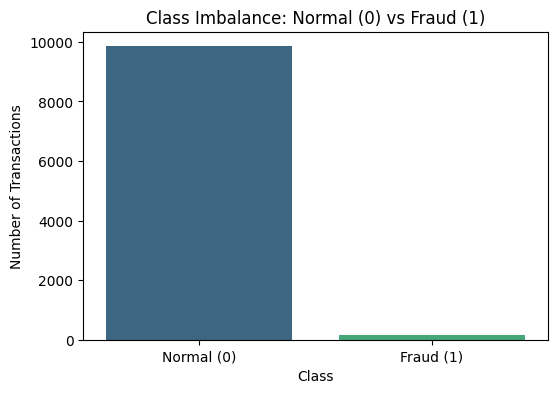

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each class
class_counts = df['Class'].value_counts()
print("Class Distribution:")
print(class_counts)

# Visualize the imbalance
plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Class Imbalance: Normal (0) vs Fraud (1)')
plt.xlabel('Class')
plt.ylabel('Number of Transactions')
plt.xticks([0, 1], ['Normal (0)', 'Fraud (1)'])
plt.show()

## Step 3: Train-Test Split
Before applying any resampling techniques, we must split our data into training and testing sets. This ensures we evaluate our model on unaltered, realistic test data.

In [ ]:
from sklearn.model_selection import train_test_split

X_data = df.drop('Class', axis=1)
y_data = df['Class']

# 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_data
)

print(f"Training set size: {X_train.shape[0]} transactions")
print(f"Testing set size: {X_test.shape[0]} transactions")

Training set size: 8000 transactions
Testing set size: 2000 transactions


## Step 4: Apply SMOTE (Oversampling)
Using SMOTE (Synthetic Minority Over-sampling Technique) helps balance our training dataset by creating synthetic examples of fraud.

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())
print("\nAfter SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

Before SMOTE:
Class
0    7878
1     122
Name: count, dtype: int64

After SMOTE:
Class
0    7878
1    7878
Name: count, dtype: int64


## Step 5: Train and Evaluate Random Forest Model
Now, we train a Random Forest Classifier using our SMOTE-balanced training data.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Initialize and train the model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_resampled, y_train_resampled)

# Make predictions on test set
y_pred = rf_model.predict(X_test)
y_probs = rf_model.predict_proba(X_test)[:, 1]

# Print evaluation metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_probs):.4f}")

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1969
           1       0.18      0.19      0.18        31

    accuracy                           0.97      2000
   macro avg       0.58      0.59      0.59      2000
weighted avg       0.97      0.97      0.97      2000

ROC-AUC Score: 0.7647


## Step 6: Discuss Trade-offs & Business Decision Thresholds
In fraud detection, there is always a trade-off:
* **High Recall**: We catch almost all fraud, but generate many false alarms (annoying customers).
* **High Precision**: When we flag fraud, we are almost certainly correct, but we might let some actual fraud slide through.

Let's plot the Precision-Recall curve to find the best threshold.

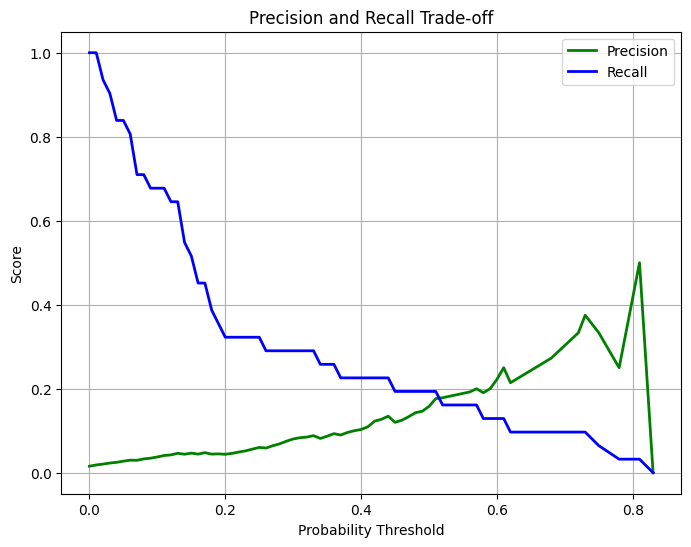

In [ ]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

plt.figure(figsize=(8, 6))
plt.plot(thresholds, precisions[:-1], label='Precision', color='g', lw=2)
plt.plot(thresholds, recalls[:-1], label='Recall', color='b', lw=2)
plt.title('Precision and Recall Trade-off')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()